In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

### Mask definition

In [2]:
def deseasonalize(data_arr):
    #compute monthly mean
    seasonal_mean = data_arr.groupby('time.month').mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.month') - seasonal_mean
    return deseasonalized_data_arr

In [3]:
def find_box_corners(plon,plat,lon_edge,lat_edge):
    lat_min, lat_max = (plat-lat_edge/2)-20,plat+(lat_edge/2)
    lon_min, lon_max = (plon-lon_edge/2),plon+(lon_edge/2)
    if lon_max % 2.5 == 0:
        lon_max -= 0.0001
    if lat_max % 2.5 == 0:
        lat_max -= 0.0001
    return lat_min,lat_max,lon_min,lon_max

In [4]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

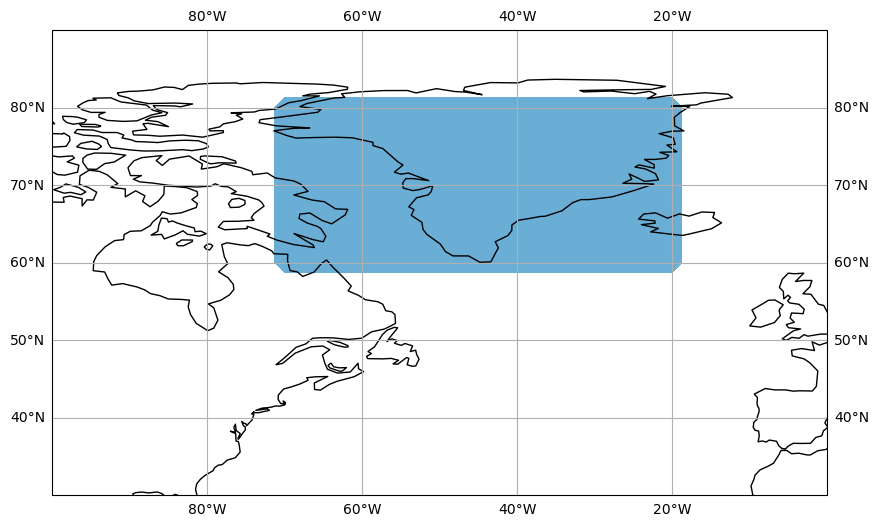

In [9]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-100, 0, 30, 90], crs=ccrs.PlateCarree())

levels = np.arange(0.5,2.5,1)

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr,levels, cmap='Blues', transform=ccrs.PlateCarree())
#plt.plot(plon,70,marker='o',color='lime',transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
#plt.title('Mask and coordinate point over Greenland Region')

# Show the plot
plt.show()

### Import data

In [55]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW_mod.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [56]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries/
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC_tyrlis_EW_mod.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dics =(dic_for_filtering_DAV,dic_for_filtering_GHA)

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries


In [57]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
np_array_GHA = GHA_filt.values
np_array_DAV = DAV_filt.values
np_arrays = (np_array_DAV,np_array_GHA)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
#ilon = list(ds_filt_DAV.lon.values).index(ds_filt_DAV.sel(lon=plon, method='nearest').lon)
#ilat = list(ds_filt_DAV.lat.values).index(ds_filt_DAV.sel(lat=plat, method='nearest').lat)
months = ['06','07','08']

# FIGURE 1 
## Trajectories

In [58]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
labels = [[],[]]
timings = [[],[]]
min_pers = (3,3,3)
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    if t > len(times.values)-5:
        break
    if month in months:
        for i,arr in enumerate(np_arrays):
            labels_of_the_day = np.unique(arr[t,mask_bool])
            for label in labels_of_the_day:
                check_cond = []
                for k in range(min_pers[i]):
                    #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                    check_cond.append(np.any(arr[t+k,mask_bool]==label))
                if label not in labels[i] and np.all(check_cond) and label!=0:
                    labels[i].append(label)
                    timings[i].append(t)

30677it [00:13, 2302.60it/s]


In [59]:
areas = [[],[]]
persistences = [[],[]]
for j in range(2):
    for label in labels[j]:
        areas[j].append(np.mean(dics[j][label]['area']))
        persistences[j].append(dics[j][label]['persistence'])

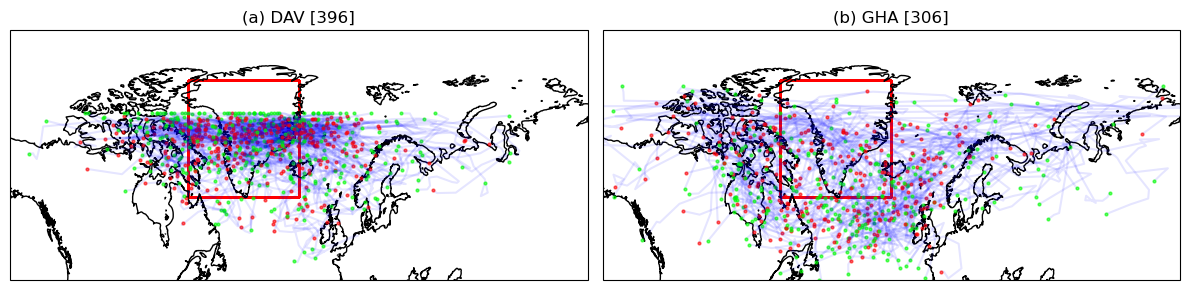

In [60]:
'''
TRAJECTORY PLOT
'''
from matplotlib.patches import Rectangle


fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), subplot_kw={'projection': ccrs.PlateCarree()})
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
titles = ['(a) DAV [' + str(len(labels[0])) + ']','(b) GHA [' + str(len(labels[1])) + ']']
datacrs = ccrs.PlateCarree()
extent =[-150,+110,45,90]
#extent =[-180,+180,45,90]

for j in range(2):
    axarr[j].coastlines()
    axarr[j].set_aspect(2.5)
    axarr[j].set_title(titles[j])
    for l,label in enumerate(labels[j]):
        #print(label)
        #print(dics[j][label])
        cm = axarr[j].plot(dics[j][label]['track'][1],dics[j][label]['track'][0],color='blue',alpha=0.1  )
        #plot the ending center of mass position
        end = axarr[j].plot(dics[j][label]['track'][1][-1],dics[j][label]['track'][0][-1],'o', markersize=2,color='r',alpha=0.6  )
        #plot the starting center of mass position
        start = axarr[j].plot(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],'o', markersize=2,color='lime',alpha=0.6  )
        #text = axarr[j].text(dics[j][label]['track'][1][0],dics[j][label]['track'][0][0],str(label)  )
        # Create a rectangle patch
        
        box = Rectangle(
            (lon_min, lat_min),  # Bottom-left corner
            lon_max - lon_min,   # Width (longitude difference)
            lat_max - lat_min + 1,   # Height (latitude difference)
            linewidth=1,
            edgecolor='red',
            facecolor='none',  # Transparent fill
            transform=datacrs  # Ensure proper projection
        )
        
        # Add the box to the plot
        axarr[j].add_patch(box)
        
    axarr[j].set_extent(extent,crs=datacrs)

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure1.pdf')
    

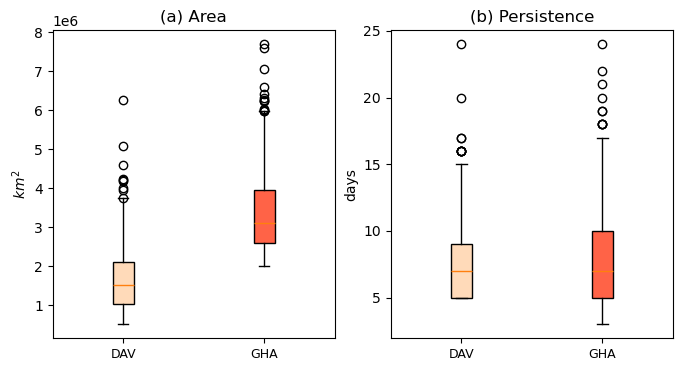

In [61]:
'''
BOXPLOT
'''

#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))

colors = ['peachpuff', 'tomato']
tick_labels = ['DAV','GHA']

axs[0].set_title('(a) Area')
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[0].set_xticklabels(tick_labels,fontsize=9)
axs[0].set_ylabel('$km^2$')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True)
axs[1].set_xticklabels(tick_labels,fontsize=9)
axs[1].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
'''
axs[2].set_title('(c) Intensity')
intensities = intensities_upstream + intensities_retrograding
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True)
axs[2].set_xticklabels(['DAV u', 'GHA u','DAV r', 'GHA r'])
colors = ['peachpuff', 'orange', 'tomato','peachpuff', 'orange', 'tomato']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
'''

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure2.pdf')

# FIGURE 2

## Composites

In [62]:
#open composite datasets
#ds_geop = xr.open_dataset('../../geop/ERA5_northem_2.5x2.5_zg500_daily_1940-2023_deseasonalized.nc')
ds_temp = xr.open_dataset('../../temperature/ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')
ds_IVT = xr.open_dataset('../../IVT/ERA5_IVT_northem_daily_2.5x2.5_jja_1940-2023_mod.nc')
ds_tp = xr.open_dataset('../../precipitation/tp_2.5x2.5_northem_daily_jja_1940-2023_mod.nc')
ds_v = xr.open_dataset('../../winds/ERA5_v_northem_daily_2.5x2.5_jja_1940-2023_mod.nc')

In [63]:
zg = ds_filt_DAV['zg']/9.81
tp = ds_tp['tp']*1000
t2m = deseasonalize(ds_temp['t2m'])
IVT = deseasonalize(ds_IVT['IVT'])
v = deseasonalize(ds_v['v'].loc[:,250,:,:])
print(zg.shape,tp.shape,t2m.shape,IVT.shape,v.shape)

(30681, 37, 144) (7728, 37, 144) (7728, 37, 144) (7728, 37, 145) (7728, 37, 145)


In [64]:
#bootstrap function for statistical significance
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

In [65]:
labels_retrograding = [[],[]]
labels_upstream = [[],[]]
zg_retrograding = [[],[]]
zg_upstream = [[],[]]
t2m_retrograding = [[],[]]
t2m_upstream = [[],[]]
tp_retrograding = [[],[]]
tp_upstream = [[],[]]
IVT_retrograding = [[],[]]
IVT_upstream = [[],[]]
v_retrograding = [[],[]]
v_upstream = [[],[]]
zg_mean = zg.mean('time')
tp_mean = tp.mean('time')
t2m_mean = t2m.mean('time')
IVT_mean = IVT.mean('time')
v_mean = v.mean('time')
count = 0
count_onset_in_GR = 0
#populating the lists
for i,arr in enumerate(np_arrays):
    for j,label in tqdm(enumerate(labels[i])):
        #print(label)
        previous_disp = []
        for k in range(10):
            if (timings[i][j]-dics[i][label]['time'] - k - 1) >= 0:
                coord1 = dics[i][label]['track'][1][timings[i][j]-dics[i][label]['time'] - k]
                coord2 = dics[i][label]['track'][1][timings[i][j]-dics[i][label]['time'] - k -1]
                previous_disp.append(coord1 - coord2)
            else:
                count_onset_in_GR += 1
        left_or_right = (dics[i][label]['track'][1][-1] - dics[i][label]['track'][1][0]) > 0
        #if np.sum(dics[i][label]['track'][1])/dics[i][label]['persistence'] - plon > 0:
        #if np.mean(previous_coords) - plon > 0:
        #if np.mean(previous_disp) < 0:
        #if not left_or_right:
        if dics[i][label]['track'][1][0] > plon:
        #if dics[i][label]['track'][1][-1] < plon:
            labels_retrograding[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                #if np.any(arr[t,:,:] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],120,50)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            zg_retrograding[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_retrograding[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            tp_retrograding[i].append((tp.loc[date,:,:]-tp_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_retrograding[i].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            v_retrograding[i].append((v.loc[date,:,:]-v_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                        
        #if np.sum(dics[i][label]['track'][1])/dics[i][label]['persistence'] - plon <= 0:
        #if np.mean(previous_coords) - plon <= 0:
        if dics[i][label]['track'][1][0] <= plon:
        #if left_or_right:
        #if np.mean(previous_disp) > 0:
        #if dics[i][label]['track'][1][-1] >= plon:
            labels_upstream[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                #if np.any(arr[t,:,:] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],120,50)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            zg_upstream[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_upstream[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            tp_upstream[i].append((tp.loc[date,:,:]-tp_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_upstream[i].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            v_upstream[i].append((v.loc[date,:,:]-v_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            #if zg.loc[date,lat_min:lat_max,lon_min:lon_max].values.shape[1] != 32:
                            #    print(lon_max,lon_min,1)
                            #if zg.loc[date,lat_min:lat_max,lon_min:lon_max].values.shape[1] == 32:
                            #    print(lon_max,lon_min,0)
#computing the composites
zg_retrograding_comp = [0,0,0]
zg_retrograding_t_st = [0,0,0]
zg_upstream_comp = [0,0,0]
zg_upstream_t_st = [0,0,0]
tp_retrograding_comp = [0,0,0]
tp_retrograding_t_st = [0,0,0]
tp_upstream_comp = [0,0,0]
tp_upstream_t_st = [0,0,0]
t2m_retrograding_comp = [0,0,0]
t2m_retrograding_t_st = [0,0,0]
t2m_upstream_comp = [0,0,0]
t2m_upstream_t_st = [0,0,0]
IVT_retrograding_comp = [0,0,0]
IVT_retrograding_t_st = [0,0,0]
IVT_upstream_comp = [0,0,0]
IVT_upstream_t_st = [0,0,0]
v_retrograding_comp = [0,0,0]
v_retrograding_t_st = [0,0,0]
v_upstream_comp = [0,0,0]
v_upstream_t_st = [0,0,0]

print(count_onset_in_GR)

396it [00:02, 162.72it/s]
306it [00:06, 47.24it/s]

6107


In [66]:
for i,var in enumerate(('DAV','GHA')):

    lat_min,lat_max,lon_min,lon_max = find_box_corners(-35,70,120,55)
    'ZG'
    zg_retrograding_comp[i] = sum(zg_retrograding[i])/len(zg_retrograding[i])
    zg_upstream_comp[i] = sum(zg_upstream[i])/len(zg_upstream[i])

    print(len(labels_retrograding[i]),len(labels_upstream[i]))
    'tp'
    tp_retrograding_comp[i] = sum(tp_retrograding[i])/len(tp_retrograding[i])# - tp_mean
    tp_retrograding_t_st[i] = abs(tp_retrograding_comp[i]/Bootstrap(tp.loc[:,lat_min:lat_max,lon_min:lon_max],len(tp_retrograding[i]),100)) > 2
    tp_upstream_comp[i] = sum(tp_upstream[i])/len(tp_upstream[i])# - tp_mean
    tp_upstream_t_st[i] = abs(tp_upstream_comp[i]/Bootstrap(tp.loc[:,lat_min:lat_max,lon_min:lon_max],len(tp_upstream[i]),100)) > 2

    't2m'
    t2m_retrograding_comp[i] = sum(t2m_retrograding[i])/len(t2m_retrograding[i])# - t2m_mean
    t2m_retrograding_t_st[i] = abs(t2m_retrograding_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_retrograding[i]),100)) > 2
    t2m_upstream_comp[i] = sum(t2m_upstream[i])/len(t2m_upstream[i])# - t2m_mean
    t2m_upstream_t_st[i] = abs(t2m_upstream_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_upstream[i]),100)) > 2
    
    'IVT'
    IVT_retrograding_comp[i] = sum(IVT_retrograding[i])/len(IVT_retrograding[i])# - IVT_mean
    IVT_retrograding_t_st[i] = abs(IVT_retrograding_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_retrograding[i]),100)) > 2
    IVT_upstream_comp[i] = sum(IVT_upstream[i])/len(IVT_upstream[i])# - IVT_mean
    IVT_upstream_t_st[i] = abs(IVT_upstream_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_upstream[i]),100)) > 2

    'v'
    v_retrograding_comp[i] = sum(v_retrograding[i])/len(v_retrograding[i])# - v_mean
    v_retrograding_t_st[i] = abs(v_retrograding_comp[i]/Bootstrap(v.loc[:,lat_min:lat_max,lon_min:lon_max],len(v_retrograding[i]),100)) > 2
    v_upstream_comp[i] = sum(v_upstream[i])/len(v_upstream[i])# - v_mean
    v_upstream_t_st[i] = abs(v_upstream_comp[i]/Bootstrap(v.loc[:,lat_min:lat_max,lon_min:lon_max],len(v_upstream[i]),100)) > 2

240 156


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 777.55it/s]


168 138


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 300.96it/s]


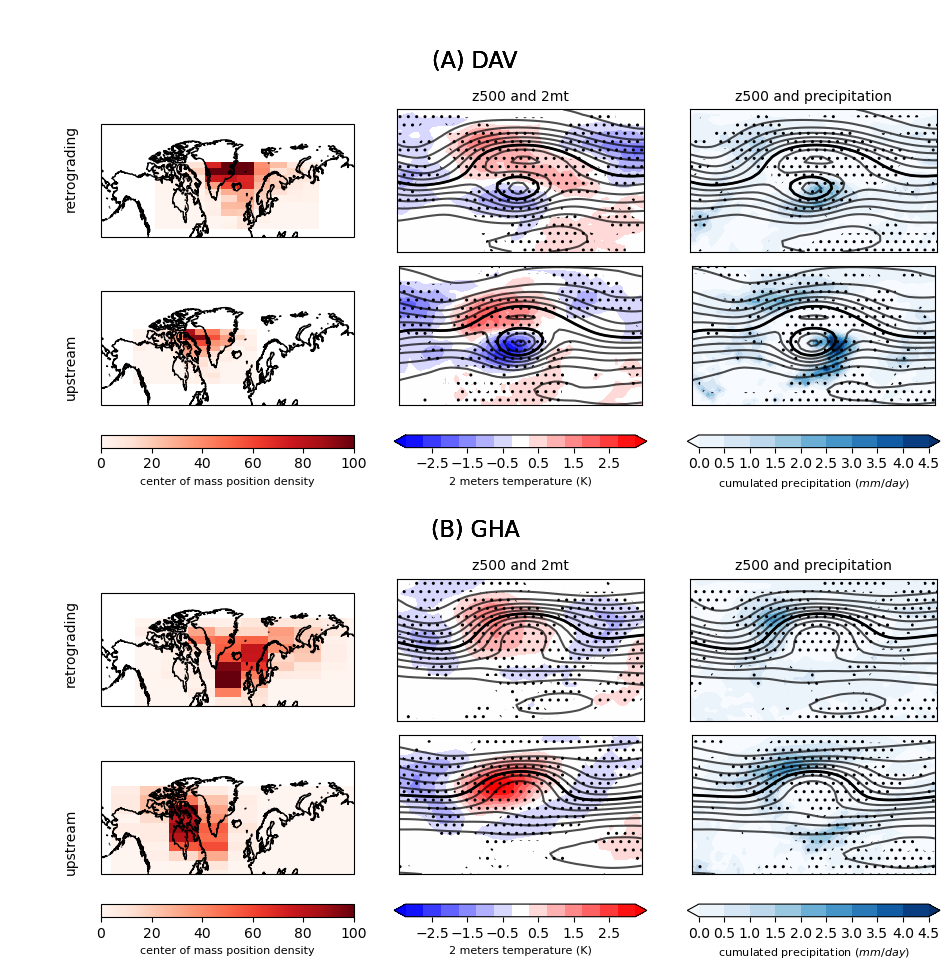

In [67]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 10
colorbar_fontsize = 8
small_titles = ['trajectories', 'z500 and 2mt', 'z500 and precipitation']

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.2,1,1,1],height_ratios=[0.6,1, 1.4, 0.6, 1, 1.4], hspace=0.1)
lon = ds_filt_DAV['lon']
lon_IVT = ds_IVT['longitude']#*2.5 - 180
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 20, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4620,6000,40)
t2m_range = np.arange(-3.25,3.3,0.5)
t2m_ticks = np.arange(-2.5,2.6,1)
tp_range = np.arange(0,5,0.5)
tp_ticks = np.arange(0,5,0.5)#(-0.0225,-0.01,int(0),0.01,0.0225)
IVT_range = np.arange(-1.1,1.2,0.2)#np.arange(np.min(IVT_retrograding_comp[0]), np.max(IVT_retrograding_comp[0]), (np.max(IVT_retrograding_comp[0])- np.min(IVT_retrograding_comp[0]))/10 )
IVT_ticks = np.arange(-1.2,1.3,0.4)#(-0.0225,-0.01,int(0),0.01,0.0225)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and i!=0 and i==1:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i],projection=ccrs.PlateCarree())
            ax.set_extent(extent, datacrs)
            ax.coastlines()
            ax.set_aspect('auto')
            #ax.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())
            'HISTOGRAMS 2D'
            'retrograding'
            if i == 1 and (j-1)%3==0:
                k = int((j-1)/3)
                xs = []
                ys = []
                for label in labels_retrograding[k]:
                    #xs.append(dics[k][label]['track'][1][-1])
                    #ys.append(dics[k][label]['track'][0][-1])
                    for x in dics[k][label]['track'][1]:
                        xs.append(x)
                    for y in dics[k][label]['track'][0]:
                        ys.append(y)
                hist = ax.hist2d(xs, ys, bins=(10, 10), cmap='Reds',vmin=0,vmax=100,transform=datacrs)  # Adjust bins as needed
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
            'upstream'
            if i == 1 and (j-2)%3==0:
                k = int((j-1)/3)
                xs = []
                ys = []
                for label in labels_upstream[k]:
                    #xs.append(dics[k][label]['track'][1][-1])
                    #ys.append(dics[k][label]['track'][0][-1])
                    for x in dics[k][label]['track'][1]:
                        xs.append(x)
                    for y in dics[k][label]['track'][0]:
                        ys.append(y)
                hist = ax.hist2d(xs, ys, bins=(10, 10), cmap='Reds',vmin=0,vmax=100,transform=datacrs)  # Adjust bins as needed
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                cb = fig.colorbar(hist[3], orientation='horizontal')
                cb.set_label('center of mass position density',size=colorbar_fontsize)


                    
            '''
            'TRAJECTORIES'
            'retrograding'
            if i == 1 and (j-1)%3==0:
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                k = int((j-1)/3)
                for l,label in enumerate(labels_retrograding[k]):
                    cm = ax.plot(dics[k][label]['track'][1],dics[k][label]['track'][0],color='blue',alpha=0.2,transform=datacrs)
                    #plot the ending center of mass position
                    end = ax.plot(dics[k][label]['track'][1][-1],dics[k][label]['track'][0][-1],'o', markersize=4,color='r',alpha=0.6,transform=datacrs)
                    #plot the starting center of mass position
                    start = ax.plot(dics[k][label]['track'][1][0],dics[k][label]['track'][0][0],'o', markersize=4,color='lime',alpha=0.6,transform=datacrs)
            'upstream'
            if i == 1 and (j-2)%3==0:
                ax.set_extent([-180,+120,45,90],datacrs)
                ax.set_aspect(3)
                k = int((j-2)/3)
                for l,label in enumerate(labels_upstream[k]):
                    cm = ax.plot(dics[k][label]['track'][1],dics[k][label]['track'][0],color='blue',alpha=0.2,transform=datacrs)
                    #plot the ending center of mass position
                    end = ax.plot(dics[k][label]['track'][1][-1],dics[k][label]['track'][0][-1],'o', markersize=4,color='r',alpha=0.6,transform=datacrs)
                    #plot the starting center of mass position
                    start = ax.plot(dics[k][label]['track'][1][0],dics[k][label]['track'][0][0],'o', markersize=4,color='lime',alpha=0.6,transform=datacrs)
            '''

        if j%3 != 0 and i!=0 and i!=1:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            #ax.set_extent(extent, datacrs)
            #ax.coastlines()
            ax.set_aspect(1)#'auto')
            ax.tick_params(left = False, right = False , labelleft = False , 
                labelbottom = False, bottom = False)
            #ax.plot(plon,plat,marker='o',color='lime',transform=ccrs.PlateCarree())
            if (j-1)%3 == 0:
                ax.set_title(small_titles[i-1],fontsize=small_titles_fontsize)
            'COMPOSITES'
            't2m'
            if i == 2 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(zg_retrograding_comp[k],z_levels,alpha = alpha_cont,colors='black')
                plt.contour(zg_retrograding_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_t2m = plt.contourf(t2m_retrograding_comp[k], cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(t2m_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 2 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(zg_upstream_comp[k],z_levels,alpha = alpha_cont,colors='black')
                plt.contour(zg_upstream_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_t2m = plt.contourf(t2m_upstream_comp[k],cmap='bwr',levels=t2m_range,extend='both')
                hatchings = ax.contourf(t2m_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.']) 
                cb = fig.colorbar(shad_t2m, orientation='horizontal',ticks=t2m_ticks)
                cb.set_label('2 meters temperature (K)',size=colorbar_fontsize)

            'TP'    
            if i == 3 and (j-1)%3==0:
                k = int((j-1)/3)
                plt.contour(zg_retrograding_comp[k],z_levels,alpha = alpha_cont,colors='black')
                plt.contour(zg_retrograding_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_tp = plt.contourf(tp_retrograding_comp[k],cmap='Blues',levels=tp_range,extend='both')
                hatchings = ax.contourf(tp_retrograding_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                #fig.colorbar(shad,orientation='vertical')
            if i == 3 and (j-2)%3==0:
                k = int((j-2)/3)
                plt.contour(zg_upstream_comp[k],z_levels,alpha = alpha_cont,colors='black')
                plt.contour(zg_upstream_comp[k],[5660],alpha = 1,linewidths = 2,colors='black')
                shad_tp = plt.contourf(tp_upstream_comp[k],cmap='Blues',levels=tp_range,extend='both')
                hatchings = ax.contourf(tp_upstream_t_st[k],colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])
                cb = fig.colorbar(shad_tp, orientation='horizontal',ticks=tp_ticks)
                cb.set_label('cumulated precipitation ($mm/day$)',size=colorbar_fontsize)
        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(A) DAV' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(B) GHA' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 6:
                middle_ax.text(0.5, 0.4, '(C) MIX' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

#plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure3.pdf')

In [68]:
areas_retrograding = [[],[]]
persistences_retrograding = [[],[]]
intensities_retrograding = [[],[]]
areas_upstream = [[],[]]
persistences_upstream = [[],[]]
intensities_upstream = [[],[]]
for i in range(2):
    for l in labels_retrograding[i]:
        areas_retrograding[i].append(np.mean(dics[i][l]['area']))
        persistences_retrograding[i].append(dics[i][l]['persistence'])
        intensities_retrograding[i].append(np.mean(dics[i][l]['intensity'])/np.mean(dics[i][l]['area']))
    for l in labels_upstream[i]:
        areas_upstream[i].append(np.mean(dics[i][l]['area']))
        persistences_upstream[i].append(dics[i][l]['persistence'])
        intensities_upstream[i].append(np.mean(dics[i][l]['intensity'])/np.mean(dics[i][l]['area']))

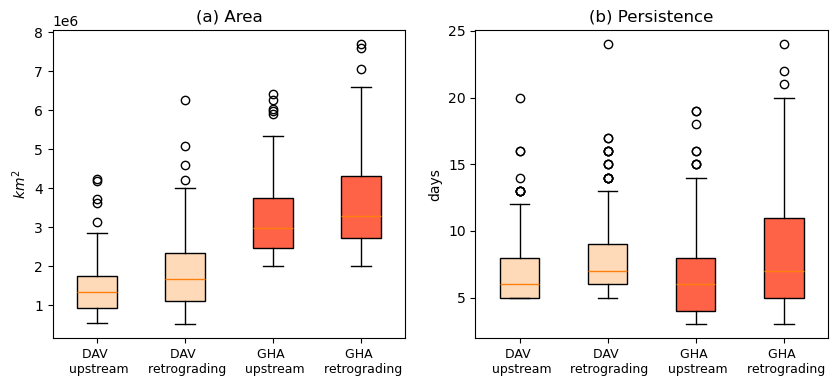

In [69]:
#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

colors = ['peachpuff','peachpuff', 'tomato', 'tomato']
tick_labels = ['DAV \n upstream','DAV \n retrograding', 'GHA \n upstream', 'GHA \n retrograding']

axs[0].set_title('(a) Area')
areas = [areas_upstream[0]] + [areas_retrograding[0]] + [areas_upstream[1]] + [areas_retrograding[1]]
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[0].set_xticklabels(tick_labels,fontsize=9)
axs[0].set_ylabel('$km^2$')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
persistences = [persistences_upstream[0]] + [persistences_retrograding[0]] + [persistences_upstream[1]] + [persistences_retrograding[1]]
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True)
axs[1].set_xticklabels(tick_labels,fontsize=9)
axs[1].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
'''
axs[2].set_title('(c) Intensity')
intensities = intensities_upstream + intensities_retrograding
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True)
axs[2].set_xticklabels(['DAV u', 'GHA u','DAV r', 'GHA r'])
colors = ['peachpuff', 'orange', 'tomato','peachpuff', 'orange', 'tomato']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
'''

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure4.pdf')

# FIGURE 4

## Frequency

In [70]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [71]:
area_coeff = (np.mean(areas[1])/np.mean(areas[0]))
print(area_coeff)

1.2921158494714116


In [72]:
area_coeff = 1.

count_DAV = np.zeros((3))
count_GHA = np.zeros((3))
list_DAV = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
list_DAV_upstream = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
list_DAV_retrograding = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
list_GHA = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
list_GHA_upstream = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
list_GHA_retrograding = xr.DataArray(np.zeros(times.shape), coords=[times], dims=["time"])
count_m = 0
freq_per_month_DAV = [[],[],[]]#np.zeros((2,len(times)))
freq_per_month_GHA = [[],[],[]]#np.zeros((2,len(times)))
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
check=0
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    #print(DAV_gr)
    month = str(time.values)[5:7]
    if month in months:
        '''
        #method1
        count_m += mask_size
        count_DAV += np.sum(DAV_gr,axis=(0))
        count_GHA += np.sum(GHA_gr,axis=(0))
        '''
        '''
        #method2
        count_m += 1
        count_DAV += np.any(DAV_gr>0)
        count_GHA += np.any(GHA_gr>0)
        '''
        #method3
        count_m += 1
        for l in np.unique(DAV_gr):
            if l in labels_retrograding[0] or l in labels_upstream[0]:
                count_DAV[0] += 1
                list_DAV[t] = 1
            if l in labels_retrograding[0]:
                count_DAV[1] += 1
                list_DAV_retrograding[t] = 1
            if l in labels_upstream[0]:
                count_DAV[2] += 1
                list_DAV_upstream[t] = 1
        for l in np.unique(GHA_gr):
            if l in labels_retrograding[1] or l in labels_upstream[1]:
                count_GHA[0] += 1
                list_GHA[t] = 1
            if l in labels_retrograding[1]:
                count_GHA[1] += 1
                list_GHA_retrograding[t] = 1
            if l in labels_upstream[1]:
                count_GHA[2] += 1
                list_GHA_upstream[t] = 1

        if month != tmp:
            #print(count_m)
            #print(count)

            check += 1
            tmp = month
            freq_per_month_DAV[0].append(count_DAV[0]*100/count_m)
            freq_per_month_GHA[0].append(count_GHA[0]*100/count_m)
            freq_per_month_DAV[1].append(count_DAV[1]*100/count_m)
            freq_per_month_GHA[1].append(count_GHA[1]*100/count_m)
            freq_per_month_DAV[2].append(count_DAV[2]*100/count_m)
            freq_per_month_GHA[2].append(count_GHA[2]*100/count_m)
            count_DAV = np.zeros((3))
            count_GHA = np.zeros((3))
            count_m = 0

print(check)

30681it [00:17, 1738.91it/s]

251


Text(0.5, 0.98, '')

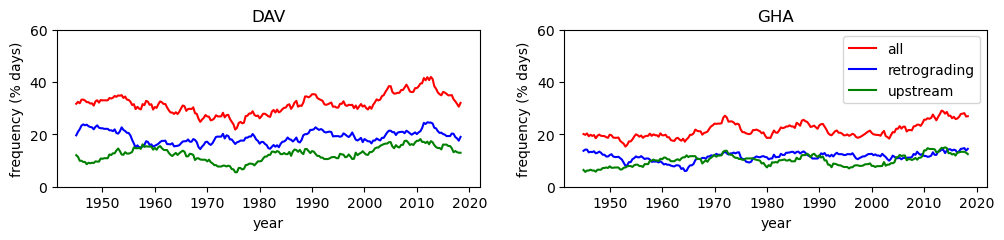

In [73]:
window = 10*len(months)
years = np.arange(1940,2024,1)
months_list = np.arange(0,len(freq_per_month_DAV[0]),1)
months_run_avg = months_list[int(window/2):int(-window/2)]
years_run_avg = []
for month in months_run_avg:
    years_run_avg.append(month/3 + 1940)

titles = ['DAV','GHA']
freqs = [freq_per_month_DAV,freq_per_month_GHA]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
for i in range(2):

    axes[i].plot(years_run_avg,running_mean(freqs[i][0],window),color='r',label='all')
    axes[i].plot(years_run_avg,running_mean(freqs[i][1],window),color='b',label='retrograding')
    axes[i].plot(years_run_avg,running_mean(freqs[i][2],window),color='g',label='upstream')
    axes[i].set_title(titles[i])
    axes[i].set_ylim((0,60))
    axes[i].set_aspect(600)

    axes[i].set_xlabel('year')
    axes[i].set_ylabel('frequency (% days)')

    axes[i].set_aspect(0.5)


plt.legend()
    
fig.suptitle('', fontsize=20)


### YMONMEAN analysis

In [74]:
ymonmean_DAV = np.zeros((3,12))
ymonmean_GHA = np.zeros((3,12))
mask_size = np.sum(mask_xr,axis=(0,1))
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    month = int(str(time.values)[5:7])-1
    for l in np.unique(DAV_gr):
        if l in labels_retrograding[0] or l in labels_upstream[0]:
            ymonmean_DAV[0][month] += 1
        if l in labels_retrograding[0]:
            ymonmean_DAV[1][month] += 1
        if l in labels_upstream[0]:
            ymonmean_DAV[2][month] += 1
    for l in np.unique(GHA_gr):
        if l in labels_retrograding[1] or l in labels_upstream[1]:
            ymonmean_GHA[0][month] += 1
        if l in labels_retrograding[1]:
            ymonmean_GHA[1][month] += 1
        if l in labels_upstream[1]:
            ymonmean_GHA[2][month] += 1

30681it [00:19, 1562.34it/s]


## Correlation Coefficients

In [75]:
print(list_DAV_upstream.shape)

(30681,)


In [76]:
list_DAV_short = list_DAV.sel(time=list_DAV.time.dt.month.isin([6,7,8]))
list_DAV_upstream_short = list_DAV_upstream.sel(time=list_DAV_upstream.time.dt.month.isin([6,7,8]))
list_DAV_retrograding_short = list_DAV_retrograding.sel(time=list_DAV_retrograding.time.dt.month.isin([6,7,8]))
list_GHA_short = list_GHA.sel(time=list_GHA.time.dt.month.isin([6,7,8]))
list_GHA_upstream_short = list_GHA_upstream.sel(time=list_GHA_upstream.time.dt.month.isin([6,7,8]))
list_GHA_retrograding_short = list_GHA_retrograding.sel(time=list_GHA_retrograding.time.dt.month.isin([6,7,8]))


In [77]:
def Jaccard(list1,list2):
    from sklearn.metrics import jaccard_score
    # Calcolo della similarità di Jaccard
    jaccard_index = jaccard_score([x == 1 for x in list1.values], [y == 1 for y in list2.values])
    return jaccard_index

In [78]:
def Matthews(list1,list2):
    from sklearn.metrics import matthews_corrcoef
    # Calcolo della similarità di Jaccard
    matthews_index = matthews_corrcoef([x == 1 for x in list1.values], [y == 1 for y in list2.values])
    return matthews_index

#### Jaccard

[['GHA', np.float64(0.2), np.float64(0.13), np.float64(0.15)], ['GHA_upstream', np.float64(0.12), np.float64(0.13), np.float64(0.07)], ['GHA_retrograding', np.float64(0.13), np.float64(0.06), np.float64(0.13)]]


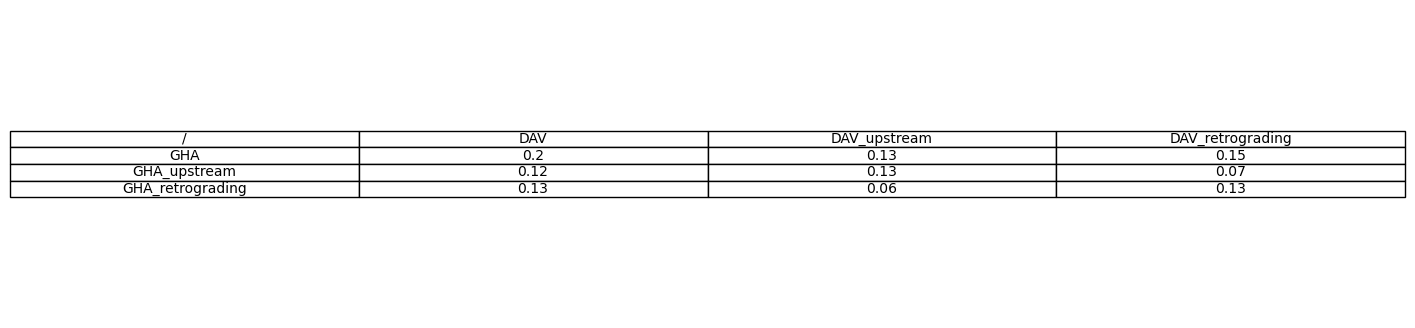

In [79]:
# Sample data
data = [['GHA', Jaccard(list_GHA_short,list_DAV_short), Jaccard(list_GHA_short,list_DAV_upstream_short),Jaccard(list_GHA_short,list_DAV_retrograding_short)], 
        ['GHA_upstream', Jaccard(list_GHA_upstream_short,list_DAV_short), Jaccard(list_GHA_upstream_short,list_DAV_upstream_short),Jaccard(list_GHA_upstream_short,list_DAV_retrograding_short)], 
        ['GHA_retrograding', Jaccard(list_GHA_retrograding_short,list_DAV_short), Jaccard(list_GHA_retrograding_short,list_DAV_upstream_short),Jaccard(list_GHA_retrograding_short,list_DAV_retrograding_short)]]

columns = ["/", "DAV", "DAV_upstream", "DAV_retrograding"]

# Function to round numbers in a mixed list
def round_numbers(row, digits=3):
    return [round(x, digits) if isinstance(x, (int, float)) else x for x in row]

rounded_data = [round_numbers(row, digits=2) for row in data]

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 4))

# Hide axes
ax.axis("tight")
ax.axis("off")

# Create table
table = ax.table(cellText=rounded_data, colLabels=columns, cellLoc='center', loc='center')

print(rounded_data)

plt.show()

#### Matthews

[['GHA', np.float64(0.122), np.float64(0.083), np.float64(0.084)], ['GHA_upstream', np.float64(0.09), np.float64(0.131), np.float64(-0.001)], ['GHA_retrograding', np.float64(0.077), np.float64(-0.009), np.float64(0.109)]]


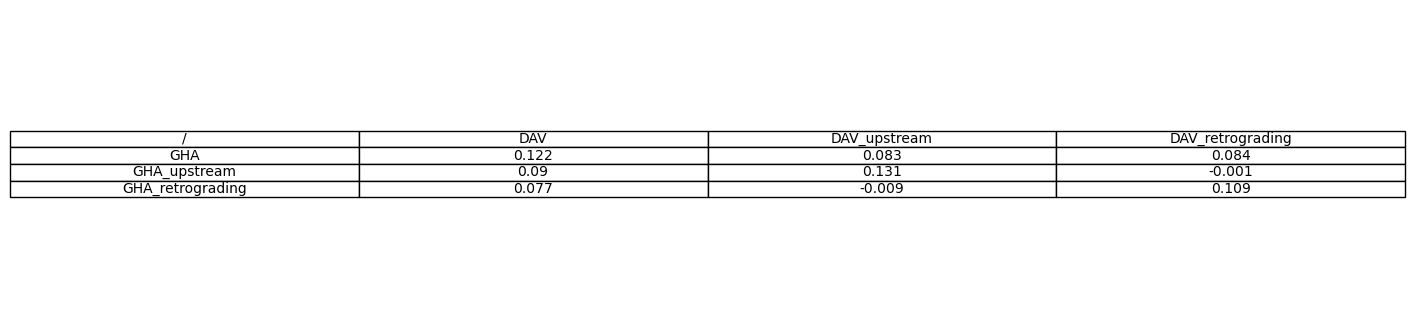

In [80]:
# Sample data
data = [['GHA', Matthews(list_GHA_short,list_DAV_short), Matthews(list_GHA_short,list_DAV_upstream_short),Matthews(list_GHA_short,list_DAV_retrograding_short)], 
        ['GHA_upstream', Matthews(list_GHA_upstream_short,list_DAV_short), Matthews(list_GHA_upstream_short,list_DAV_upstream_short),Matthews(list_GHA_upstream_short,list_DAV_retrograding_short)], 
        ['GHA_retrograding', Matthews(list_GHA_retrograding_short,list_DAV_short), Matthews(list_GHA_retrograding_short,list_DAV_upstream_short),Matthews(list_GHA_retrograding_short,list_DAV_retrograding_short)]]

columns = ["/", "DAV", "DAV_upstream", "DAV_retrograding"]

# Function to round numbers in a mixed list
def round_numbers(row, digits=3):
    return [round(x, digits) if isinstance(x, (int, float)) else x for x in row]

rounded_data = [round_numbers(row, digits=3) for row in data]

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 4))

# Hide axes
ax.axis("tight")
ax.axis("off")

# Create table
table = ax.table(cellText=rounded_data, colLabels=columns, cellLoc='center', loc='center')

print(rounded_data)

plt.show()

#### Simple Corr

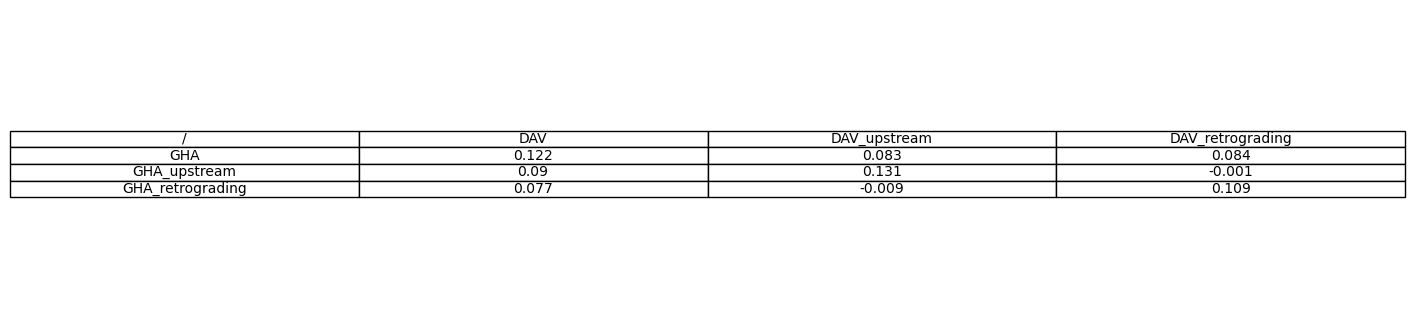

In [81]:
# Sample data
data = [['GHA', np.corrcoef(list_GHA_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_short,list_DAV_retrograding_short)[0, 1]], 
        ['GHA_upstream', np.corrcoef(list_GHA_upstream_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_upstream_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_upstream_short,list_DAV_retrograding_short)[0, 1]], 
        ['GHA_retrograding', np.corrcoef(list_GHA_retrograding_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_retrograding_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_retrograding_short,list_DAV_retrograding_short)[0, 1]]]

columns = ["/", "DAV", "DAV_upstream", "DAV_retrograding"]

# Function to round numbers in a mixed list
def round_numbers(row, digits=3):
    return [round(x, digits) if isinstance(x, (int, float)) else x for x in row]

rounded_data = [round_numbers(row, digits=3) for row in data]

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 4))

# Hide axes
ax.axis("tight")
ax.axis("off")

# Create table
table = ax.table(cellText=rounded_data, colLabels=columns, cellLoc='center', loc='center')

plt.show()

## Correlation Coefficients (monthly time series)

In [82]:
print(list_DAV_upstream.shape)

(30681,)


In [83]:
list_DAV_short = data_arrays_freq_DAV[0]
list_DAV_upstream_short = data_arrays_freq_DAV[2]
list_DAV_retrograding_short = data_arrays_freq_DAV[1]
list_GHA_short = data_arrays_freq_GHA[0]
list_GHA_upstream_short = data_arrays_freq_GHA[2]
list_GHA_retrograding_short = data_arrays_freq_GHA[1]


NameError: name 'data_arrays_freq_DAV' is not defined

In [ ]:
# Sample data
data = [['GHA', np.corrcoef(list_GHA_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_short,list_DAV_retrograding_short)[0, 1]], 
        ['GHA_upstream', np.corrcoef(list_GHA_upstream_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_upstream_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_upstream_short,list_DAV_retrograding_short)[0, 1]], 
        ['GHA_retrograding', np.corrcoef(list_GHA_retrograding_short,list_DAV_short)[0, 1], np.corrcoef(list_GHA_retrograding_short,list_DAV_upstream_short)[0, 1],np.corrcoef(list_GHA_retrograding_short,list_DAV_retrograding_short)[0, 1]]]

columns = ["/", "DAV", "DAV_upstream", "DAV_retrograding"]

# Function to round numbers in a mixed list
def round_numbers(row, digits=3):
    return [round(x, digits) if isinstance(x, (int, float)) else x for x in row]

rounded_data = [round_numbers(row, digits=3) for row in data]

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 4))

# Hide axes
ax.axis("tight")
ax.axis("off")

# Create table
table = ax.table(cellText=rounded_data, colLabels=columns, cellLoc='center', loc='center')

plt.show()